Generation: 1 Best Fitness: 0.7921
Generation: 2 Best Fitness: 0.8109
Generation: 3 Best Fitness: 0.8109
Generation: 4 Best Fitness: 0.8203
Generation: 5 Best Fitness: 0.8203
Generation: 6 Best Fitness: 0.992
Generation: 7 Best Fitness: 0.992
Generation: 8 Best Fitness: 0.992
Generation: 9 Best Fitness: 0.992
Generation: 10 Best Fitness: 0.992
Generation: 11 Best Fitness: 0.992
Generation: 12 Best Fitness: 0.992
Generation: 13 Best Fitness: 0.992
Generation: 14 Best Fitness: 0.992
Generation: 15 Best Fitness: 0.992
Generation: 16 Best Fitness: 0.992
Generation: 17 Best Fitness: 0.992
Generation: 18 Best Fitness: 0.992
Generation: 19 Best Fitness: 0.992
Generation: 20 Best Fitness: 0.992
Generation: 21 Best Fitness: 0.992
Generation: 22 Best Fitness: 0.992
Generation: 23 Best Fitness: 0.992
Generation: 24 Best Fitness: 0.992
Generation: 25 Best Fitness: 0.992
Generation: 26 Best Fitness: 0.992
Generation: 27 Best Fitness: 0.992
Generation: 28 Best Fitness: 0.992
Generation: 29 Best Fitn

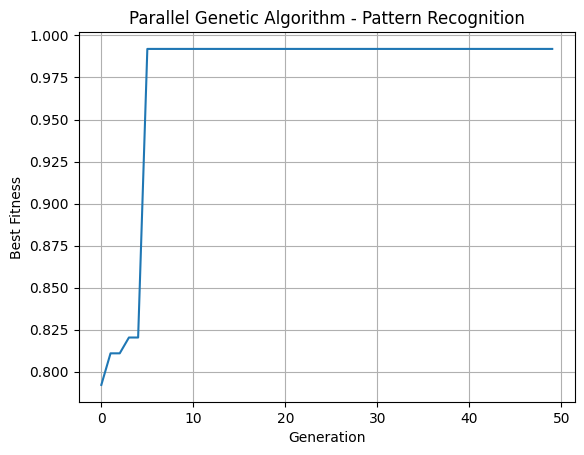

In [1]:

import numpy as np
import random
import matplotlib.pyplot as plt
from multiprocessing import Pool, cpu_count

# Create sample pattern data
np.random.seed(10)
random.seed(10)

rows = 100
columns = 20
markers = 3

data = np.random.rand(rows, columns)

# Create three related patterns
common = np.random.rand(rows)

data[:, 3] = common + np.random.normal(0, 0.05, rows)
data[:, 8] = common + np.random.normal(0, 0.05, rows)
data[:, 15] = common + np.random.normal(0, 0.05, rows)

data = np.clip(data, 0, 1)

# Fitness function using cosine similarity
def fitness(args):
    chromosome, data = args

    selected = np.where(chromosome == 1)[0]

    scores = []

    for i in range(len(selected)):
        for j in range(i + 1, len(selected)):

            a = data[:, selected[i]]
            b = data[:, selected[j]]

            cosine = np.dot(a, b) / (
                np.linalg.norm(a) * np.linalg.norm(b) + 1e-10
            )

            scores.append(cosine)

    return np.mean(scores)


# Create chromosome with exactly 3 selected markers
def create_chromosome():
    chromosome = np.zeros(columns, dtype=int)
    positions = random.sample(range(columns), markers)

    for p in positions:
        chromosome[p] = 1

    return chromosome


# Tournament selection
def selection(population, scores):
    selected = random.sample(range(len(population)), 3)
    best = max(selected, key=lambda x: scores[x])

    return population[best].copy()


# Modified one-point crossover
def crossover(p1, p2):
    point = random.randint(1, columns - 1)

    child = np.concatenate((p1[:point], p2[point:]))

    ones = list(np.where(child == 1)[0])
    zeros = list(np.where(child == 0)[0])

    while len(ones) > markers:
        pos = random.choice(ones)
        child[pos] = 0
        ones.remove(pos)

    while len(ones) < markers:
        pos = random.choice(zeros)
        child[pos] = 1
        zeros.remove(pos)
        ones.append(pos)

    return child


# Mutation: swap one selected and one unselected marker
def mutation(chromosome):
    if random.random() < 0.3:
        ones = list(np.where(chromosome == 1)[0])
        zeros = list(np.where(chromosome == 0)[0])

        a = random.choice(ones)
        b = random.choice(zeros)

        chromosome[a] = 0
        chromosome[b] = 1

    return chromosome


# Main parallel genetic algorithm
if __name__ == "__main__":

    population_size = 40
    generations = 50

    population = [
        create_chromosome()
        for _ in range(population_size)
    ]

    best_history = []

    workers = min(4, cpu_count())

    # Parallel fitness calculation
    with Pool(processes=workers) as pool:

        for generation in range(generations):

            tasks = [(individual, data) for individual in population]

            scores = pool.map(fitness, tasks)

            best_index = np.argmax(scores)

            best_history.append(scores[best_index])

            print(
                "Generation:", generation + 1,
                "Best Fitness:", round(scores[best_index], 4)
            )

            new_population = []

            # Elitism
            new_population.append(
                population[best_index].copy()
            )

            while len(new_population) < population_size:

                p1 = selection(population, scores)
                p2 = selection(population, scores)

                child = crossover(p1, p2)
                child = mutation(child)

                new_population.append(child)

            population = new_population

    # Final result
    final_scores = [
        fitness((individual, data))
        for individual in population
    ]

    best = population[np.argmax(final_scores)]

    print("\nBest Pattern Found:")
    print("Selected Markers:", np.where(best == 1)[0])

    print("Best Fitness:", max(final_scores))

    # Plot fitness graph
    plt.plot(best_history)
    plt.xlabel("Generation")
    plt.ylabel("Best Fitness")
    plt.title("Parallel Genetic Algorithm - Pattern Recognition")
    plt.grid()
    plt.show()
